# LDA_Overfit — LDA Feature Importance (AM-Filtered HP + Unfiltered CB)

## Overview

This notebook fits **Linear Discriminant Analysis (LDA)** on the full dataset without
cross-validation — an intentional overfit used exclusively for **feature interpretation
and visualisation**. Two tasks are run in parallel:

- **HP (Healthy vs PDAC)**: AM-filtered mutations (`am_pathogenicity ≥ 0.564`), healthy
  individuals subsampled to the TCGA somatic count distribution before filtering.
- **CB (Classical vs Basal-like)**: all TCGA somatic mutations, no AM filter.

Bootstrap resampling (N=100) quantifies LDA coefficient stability, not generalisation.
Part of BRP *"AlphaMissense in Personalized Pancreatic Cancer Diagnostics"* (Leiden / LACDR, 2026),
addressing RQ5–RQ7 (pathway-level mutation burden for PDAC subtyping).

## Data

**Input**
- `merged_tcga_1000G.parquet` — long-format somatic (TCGA-PAAD) + germline (1000G) mutations
  with `am_pathogenicity`; columns `source`, `sample_id`, `gene_symbol`, `gene_name`,
  `am_pathogenicity`, `subtype`.
- `reactome_hierarchy/` — Reactome flat files; Hallmark via GSEApy (`MSigDB_Hallmark_2020`).
- `Analyses/driver_like_genes.txt` — 77 PDAC driver-like genes (4 canonical + 73 custom).

**Processing**
- HP: TCGA mutations with `am_pathogenicity ≥ AM_THRESHOLD (0.564)`; healthy individuals
  subsampled (k drawn from TCGA somatic count distribution, seed 42), then AM-filtered.
- CB: all TCGA mutations for 142 labelled patients (81 Classical, 61 Basal-like); no AM filter.
- Both tasks encode 1,662 binary pathway features (Hallmark + Reactome L2–L4). Features
  standardised (zero mean, unit variance) before LDA fitting.

**Output**
- `results/LDA_Overfit_feature_importance.{png,svg}` — diverging bar chart, top-20 pathways per task with bootstrap 95 % CI.
- `results/LDA_Overfit_scatter.{png,svg}` — hierarchical scatter (HP vs CB LDA scores, all groups).
- `results/LDA_Overfit_feature_importance.txt` — ranked pathway table with gene mutation fractions.

## Method

| Parameter | Value | Description |
|-----------|-------|-------------|
| `AM_THRESHOLD` | `0.564` | AlphaMissense pathogenic cutoff (HP task only) |
| `N_BOOTSTRAP` | `100` | Bootstrap iterations for coefficient CI |
| `CB_SUBSAMPLE_FRAC` | `0.80` | Fraction of CB patients per bootstrap draw (without replacement) |
| `MAX_REACTOME_LEVEL` | `3` | Max BFS depth included (BFS 1–3 → Reactome L2–L4) |
| `RANDOM_SEED` | `42` | Master seed; draw *i* uses seed `RANDOM_SEED + i + 1` |

- **LDA**: `LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')` (Ledoit-Wolf); full-data fit — no CV.
- **HP bootstrap**: re-runs healthy subsampling N times (TCGA fixed); bar heights = mean coefficient; ranking = mean |coef|; error bars = 95 % CI (2.5–97.5 percentile).
- **CB bootstrap**: draws `CB_SUBSAMPLE_FRAC × 142` patients without replacement per iteration; bar heights = full-data coefficient; error bars = 95 % CI of subsample distribution.
- **Rank stability %**: fraction of bootstrap iterations where pathway appears in top 20 by |coefficient|.
- **Reproducibility**: 1000G variants sorted by `(sample_id, gene, am_pathogenicity)` before groupby to ensure deterministic within-group ordering across kernel restarts.

## Content

| # | Name | Description |
|---|------|-------------|
| 0 | Setup | Imports, constants, paths (`DATA_DIR`, `RESULTS_DIR`, `DRIVER_FILE`), colour palette, driver-gene tier definitions |
| 1 | Build Pathway Gene Sets | Reactome L2–L4 (BFS 1–3) + Hallmark; assemble 1,662-pathway `pw_sets` dict; `pw_level_tag` helper |
| 2 | Patient IDs, Labels, and TCGA Count Distribution | Load TCGA metadata; exclude hypermutator (TMB > 500); derive HP and CB patient ID lists; empirical TCGA somatic count distribution for healthy subsampling |
| 3 | Build HP Feature Matrices | AM-filtered TCGA gene sets; per-individual healthy subsampling + AM filter; binary (n_samples × 1,662) matrices |
| 4 | Build CB Feature Matrix | All TCGA mutations for 142 labelled patients; binary (142 × 1,662) matrix |
| 5 | Fit LDA and Extract Top-20 | Standardise; fit HP and CB LDA; rank 1,662 pathways by \|coefficient\| |
| 5b | Metrics — Classical vs Basal-like (In-Sample) | ROC, PRC, confusion matrix for CB LDA (in-sample / overfit) |
| 5c | Metrics — Healthy vs PDAC (In-Sample) | ROC, PRC, confusion matrix for HP LDA (in-sample / overfit) |
| 6b | Bootstrap Uncertainty | HP: re-run healthy subsampling N=100×; CB: 80 % subsample N=100×; CI computation; rank stability % |
| 6 | Diverging Bar Chart | Side-by-side horizontal bar charts; top-20 per task; bootstrap 95 % CI; stability % annotation |
| 7 | Hierarchical Scatter Plot | X = HP LDA score, Y = CB LDA score; all 4 groups (healthy subsampled to 300 for clarity) |
| 8 | Per-Gene Mutation Counts | Derive per-gene mutation fractions from the same gene sets used for LDA features |
| 9 | Generate Text File | Write ranked pathway table with gene breakdown (canonical / custom / top-10 other) to `.txt` |

## 0. Setup

In [1]:
from collections import defaultdict, deque
import re
import warnings
from pathlib import Path

import gseapy as gp
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score, roc_curve, auc,
    ConfusionMatrixDisplay,
    precision_recall_curve, average_precision_score,
)
from tqdm.auto import tqdm

pl.Config.set_tbl_rows(-1)
pl.Config.set_tbl_cols(-1)

# ── Constants ──────────────────────────────────────────────────────────────────
AM_THRESHOLD       = 0.564
TOP_N              = 20
TOP_OTHER          = 10
RANDOM_SEED        = 42
MAX_REACTOME_LEVEL = 3   # highest BFS depth (0-indexed); 3 → L4
MIN_REACTOME_LEVEL = 1   # lowest BFS depth; 0 → L1

BOOTSTRAP         = True    # False = skip, draw bars as today (fast)
N_BOOTSTRAP       = 100
CB_SUBSAMPLE_FRAC = 0.80    # fraction of CB patients per iteration (without replacement)

# ── Paths ──────────────────────────────────────────────────────────────────────
DATA_DIR     = Path('C:/Users/daane/Desktop/DATA')
PARQUET      = DATA_DIR / 'merged_tcga_1000G.parquet'
REACTOME_DIR = DATA_DIR / 'reactome_hierarchy'
RESULTS_DIR  = DATA_DIR / 'results'
REPO_ROOT    = Path('C:/Users/daane/Desktop/GitHub Repos/Bachelor_Research_Project')
DRIVER_FILE  = REPO_ROOT / 'Analyses/driver_like_genes.txt'

RESULTS_DIR.mkdir(exist_ok=True)

# ── Colours ────────────────────────────────────────────────────────────────────
# Wong colour-blind-safe palette (8 colours, no gray or yellow).
WONG = {
    'orange':    '#E69F00',
    'sky_blue':  '#56B4E9',
    'green':     '#009E73',
    'yellow':    '#F0E442',
    'blue':      '#0072B2',
    'vermilion': '#D55E00',
    'pink':      '#CC79A7',
}

# Scatter-plot class colours.  Gray and the warm yellow/deep red are not in
# the Wong palette but are chosen to be distinguishable under common forms of
# colour-blindness (protanopia/deuteranopia): blue and gray are unambiguous;
# warm yellow (#E6C229) is bright/light and deep red (#C72C2C) is dark, so
# they contrast in luminance even when hue perception is impaired.
GRAY        = '#999999'  # Uncertain
YELLOW_WARM = '#E6C229'  # Classical  — warm ochre, more depth than pure yellow
RED_DEEP    = '#C72C2C'  # Basal-like — pure deep red, no orange undertone

# ── Driver gene tiers ──────────────────────────────────────────────────────────
CANONICAL_DRIVERS = {'KRAS', 'TP53', 'SMAD4', 'CDKN2A'}

_driver_lines   = DRIVER_FILE.read_text(encoding='utf-8').strip().splitlines()
_gene_list_line = next(l for l in reversed(_driver_lines)
                       if l.strip() and not l.startswith('#'))
ALL_DRIVER_GENES = {g.strip() for g in _gene_list_line.split(',')}
CUSTOM_DRIVERS   = ALL_DRIVER_GENES - CANONICAL_DRIVERS

print(f'Data dir   : {DATA_DIR}')
print(f'Parquet    : {PARQUET.exists()}')
print(f'Results dir: {RESULTS_DIR}')
print(f'Driver genes: {len(ALL_DRIVER_GENES)} total '
      f'({len(CANONICAL_DRIVERS)} canonical, {len(CUSTOM_DRIVERS)} custom)')
print(f'Bootstrap  : {BOOTSTRAP}  N={N_BOOTSTRAP}  CB_frac={CB_SUBSAMPLE_FRAC}')
print(f'Reactome levels: L{MIN_REACTOME_LEVEL+1}–L{MAX_REACTOME_LEVEL+1}')

Data dir   : C:\Users\daane\Desktop\DATA
Parquet    : True
Results dir: C:\Users\daane\Desktop\DATA\results
Driver genes: 77 total (4 canonical, 73 custom)
Bootstrap  : True  N=100  CB_frac=0.8
Reactome levels: L2–L4


## 1. Build Pathway Gene Sets (Hallmark + Reactome L0–L2)

In [2]:
# ── Reactome: parse cached flat files ─────────────────────────────────────────
pw_txt  = (REACTOME_DIR / 'ReactomePathways.txt').read_text(encoding='utf-8')
rel_txt = (REACTOME_DIR / 'ReactomePathwaysRelation.txt').read_text(encoding='utf-8')
gmt_txt = (REACTOME_DIR / 'ReactomePathways.gmt').read_text(encoding='utf-8')

# Human pathway ID → name
human_id_to_name: dict[str, str] = {}
for line in pw_txt.strip().split('\n'):
    parts = line.split('\t')
    if len(parts) >= 3 and parts[2].strip() == 'Homo sapiens':
        human_id_to_name[parts[0].strip()] = parts[1].strip()
human_ids = set(human_id_to_name)

# Build human-only DAG
parent_to_children: dict[str, set] = defaultdict(set)
child_to_parents:   dict[str, set] = defaultdict(set)
for line in rel_txt.strip().split('\n'):
    parts = line.strip().split('\t')
    if len(parts) < 2:
        continue
    parent, child = parts[0], parts[1]
    if parent in human_ids and child in human_ids:
        parent_to_children[parent].add(child)
        child_to_parents[child].add(parent)

# BFS depth assignment
all_in_dag = set(parent_to_children) | set(child_to_parents)
roots      = {pid for pid in all_in_dag if pid not in child_to_parents}
level_of: dict[str, int] = {}
queue = deque()
for r in roots:
    level_of[r] = 0
    queue.append(r)
while queue:
    node = queue.popleft()
    for child in parent_to_children.get(node, set()):
        if child not in level_of:
            level_of[child] = level_of[node] + 1
            queue.append(child)

# GMT: stable Reactome ID → {name, genes}
gmt_by_id:  dict[str, dict] = {}
name_to_id: dict[str, str]  = {}
for line in gmt_txt.strip().split('\n'):
    parts = line.split('\t')
    if len(parts) < 3:
        continue
    name  = parts[0]
    url   = parts[1]
    genes = {g.strip() for g in parts[2:] if g.strip()}
    m = re.search(r'R-HSA-\d+', url)
    if not m:
        continue
    rid = m.group(0)
    gmt_by_id[rid]   = {'name': name, 'genes': genes}
    name_to_id[name] = rid

# ── Hallmark gene sets ─────────────────────────────────────────────────────────
_raw_hallmark = gp.get_library('MSigDB_Hallmark_2020')
hallmark_sets = {k: set(v) for k, v in _raw_hallmark.items()}

# ── Reactome levels MIN_REACTOME_LEVEL–MAX_REACTOME_LEVEL ─────────────────────
reactome_selected: dict[str, set] = {}
for rid, info in gmt_by_id.items():
    if MIN_REACTOME_LEVEL <= level_of.get(rid, 99) <= MAX_REACTOME_LEVEL and info['genes']:
        reactome_selected[info['name']] = info['genes']

# ── Combined pw_sets (Hallmark ∪ selected Reactome levels) ────────────────────
pw_sets: dict[str, set] = {}
for name, genes in hallmark_sets.items():
    pw_sets[f'HALLMARK_{name}'] = genes
for name, genes in reactome_selected.items():
    key = f'REACTOME_{name}'
    if key not in pw_sets:
        pw_sets[key] = genes

pw_names = sorted(pw_sets.keys())

# ── Level tag helper ───────────────────────────────────────────────────────────
# BFS level 0 → Reactome-L1, level 1 → Reactome-L2, level 2 → Reactome-L3, etc.
def pw_level_tag(pw_name: str) -> str:
    """Return '(Reactome-LN)' for Reactome pathways; '' for Hallmark."""
    if not pw_name.startswith('REACTOME_'):
        return ''
    base = pw_name[len('REACTOME_'):]
    rid  = name_to_id.get(base)
    if rid is None:
        return ''
    lv = level_of.get(rid)
    return f'(Reactome-L{lv + 1})' if lv is not None else ''

for lv in range(MIN_REACTOME_LEVEL, MAX_REACTOME_LEVEL + 1):
    n = sum(1 for rid in gmt_by_id if level_of.get(rid) == lv)
    print(f'Reactome-L{lv + 1}: {n} pathways')
print(f'Reactome-L{MIN_REACTOME_LEVEL+1}–L{MAX_REACTOME_LEVEL+1} with genes: {len(reactome_selected)}')
print(f'Hallmark pathways: {len(hallmark_sets)}')
print(f'Total pw_sets: {len(pw_sets)}')

Reactome-L2: 188 pathways
Reactome-L3: 504 pathways
Reactome-L4: 920 pathways
Reactome-L2–L4 with genes: 1612
Hallmark pathways: 50
Total pw_sets: 1662


## 2. Patient IDs, Labels, and TCGA Count Distribution

In [3]:
# ── Load metadata ──────────────────────────────────────────────────────────────
df_meta = (
    pl.read_parquet(PARQUET, columns=['source', 'sample_id', 'subtype'])
    .unique('sample_id')
)

# TCGA TMB for hypermutator exclusion and count distribution
tmb_df = (
    pl.read_parquet(PARQUET, columns=['source', 'sample_id'])
    .filter(pl.col('source') == 'TCGA')
    .group_by('sample_id').agg(pl.len().alias('tmb'))
)
hypermutator_ids = set(
    tmb_df.filter(pl.col('tmb') > 500)['sample_id'].to_list()
)

df_tcga_meta = (
    df_meta
    .filter(
        (pl.col('source') == 'TCGA') &
        ~pl.col('sample_id').is_in(hypermutator_ids)
    )
    .sort('sample_id')
)

# Empirical TCGA somatic count distribution (for healthy subsampling)
tcga_counts = (
    tmb_df
    .filter(pl.col('sample_id').is_in(df_tcga_meta['sample_id'].to_list()))
    ['tmb'].to_numpy()
)

# ── Patient ID lists ───────────────────────────────────────────────────────────
SUBTYPE_CLASSICAL = 'classical'
SUBTYPE_BASAL     = 'basal-like'

df_clvbl     = df_tcga_meta.filter(pl.col('subtype').is_in([SUBTYPE_CLASSICAL, SUBTYPE_BASAL]))
df_uncertain = df_tcga_meta.filter(pl.col('subtype').is_null())
df_1kg_meta  = df_meta.filter(pl.col('source') == '1000G')

clvbl_ids     = df_clvbl['sample_id'].to_list()
uncertain_ids = df_uncertain['sample_id'].to_list()
healthy_ids   = df_1kg_meta['sample_id'].sort().to_list()
pdac_ids      = clvbl_ids + uncertain_ids  # all 167 TCGA patients

y_binary      = (df_clvbl['subtype'] == SUBTYPE_BASAL).cast(pl.Int8).to_numpy()
classical_ids = [clvbl_ids[i] for i in range(len(clvbl_ids)) if y_binary[i] == 0]
basal_ids     = [clvbl_ids[i] for i in range(len(clvbl_ids)) if y_binary[i] == 1]

print(f'Classical  : {len(classical_ids)}')
print(f'Basal-like : {len(basal_ids)}')
print(f'Uncertain  : {len(uncertain_ids)}')
print(f'Total PDAC : {len(pdac_ids)}')
print(f'Healthy    : {len(healthy_ids)}')
print(f'Somatic count distribution: median={np.median(tcga_counts):.0f}, '
      f'mean={tcga_counts.mean():.1f}, '
      f'min={tcga_counts.min()}, max={tcga_counts.max()}')

Classical  : 81
Basal-like : 61
Uncertain  : 25
Total PDAC : 167
Healthy    : 3202
Somatic count distribution: median=24, mean=26.5, min=1, max=84


## 3. Build HP Feature Matrices (AM-Filtered)

**TCGA:** keep only mutations with `am_pathogenicity ≥ 0.564`.
**Healthy:** draw k variants from each individual's full pool (no AF filter), using k sampled
from the TCGA count distribution; then apply `am_pathogenicity ≥ 0.564` to the subsample.

In [4]:
def build_binary_matrix(
    sample_ids: list[str],
    sample_gene_sets: dict[str, set],
    pw_names: list[str],
    pw_sets: dict[str, set],
) -> np.ndarray:
    """Binary (n_samples × n_pathways) matrix from per-sample gene sets."""
    pw_to_idx = {pw: i for i, pw in enumerate(pw_names)}
    gene_to_pws: dict[str, list[int]] = defaultdict(list)
    for pw, genes in pw_sets.items():
        pi = pw_to_idx[pw]
        for g in genes:
            gene_to_pws[g].append(pi)

    X = np.zeros((len(sample_ids), len(pw_names)), dtype=np.float32)
    for i, sid in enumerate(sample_ids):
        for g in sample_gene_sets.get(sid, set()):
            for pi in gene_to_pws.get(g, []):
                X[i, pi] = 1.0
    return X


# ── HP: TCGA AM-filtered gene sets ────────────────────────────────────────────
df_tcga_am = (
    pl.read_parquet(
        PARQUET,
        columns=['source', 'sample_id', 'gene_symbol', 'gene_name', 'am_pathogenicity'],
    )
    .filter(
        (pl.col('source') == 'TCGA') &
        pl.col('sample_id').is_in(pdac_ids) &
        (pl.col('am_pathogenicity') >= AM_THRESHOLD)
    )
    .with_columns(pl.coalesce(['gene_symbol', 'gene_name']).alias('gene'))
    .drop_nulls('gene')
    .select(['sample_id', 'gene'])
    .unique()
)

tcga_hp_gene_sets: dict[str, set] = {}
for row in (
    df_tcga_am.group_by('sample_id')
    .agg(pl.col('gene'))
    .iter_rows(named=True)
):
    tcga_hp_gene_sets[row['sample_id']] = set(row['gene'])

print(f'TCGA HP: {len(tcga_hp_gene_sets)} / {len(pdac_ids)} patients '
      f'have ≥1 AM-pathogenic mutation')

# ── HP: Healthy subsampled + AM-filtered gene sets ────────────────────────────
df_1kg_all = (
    pl.read_parquet(
        PARQUET,
        columns=['source', 'sample_id', 'gene_symbol', 'gene_name', 'am_pathogenicity'],
    )
    .filter(pl.col('source') == '1000G')
    .with_columns(pl.coalesce(['gene_symbol', 'gene_name']).alias('gene'))
    .drop_nulls('gene')
    .select(['sample_id', 'gene', 'am_pathogenicity'])
)
print(f'1000G total variants loaded: {len(df_1kg_all):,}')

# Sort by (sample_id, gene, am_pathogenicity) before groupby so that the
# within-group list order is deterministic across kernel restarts.
# Without this sort, Polars group_by does not guarantee within-group row
# ordering, making rng.choice(indices) sample different variants each run
# despite a fixed seed.
indiv_variants: dict[str, list] = {}
for row in (
    df_1kg_all
    .sort(['sample_id', 'gene', 'am_pathogenicity'])
    .group_by('sample_id', maintain_order=False)
    .agg([pl.col('gene'), pl.col('am_pathogenicity')])
    .iter_rows(named=True)
):
    indiv_variants[row['sample_id']] = list(
        zip(row['gene'], row['am_pathogenicity'])
    )

# Subsample-then-AM-filter: one draw per individual (seed 42)
rng = np.random.default_rng(RANDOM_SEED)

healthy_hp_gene_sets: dict[str, set] = {}
for sid in healthy_ids:
    variants = indiv_variants.get(sid, [])
    k = int(rng.choice(tcga_counts))
    k = min(k, len(variants))
    if k == 0:
        healthy_hp_gene_sets[sid] = set()
        continue
    indices = rng.choice(len(variants), size=k, replace=False)
    genes_out = set()
    for j in indices:
        g, am = variants[j]
        if am >= AM_THRESHOLD:
            genes_out.add(g)
    healthy_hp_gene_sets[sid] = genes_out

n_healthy_with_any = sum(1 for s in healthy_hp_gene_sets.values() if s)
print(f'Healthy with ≥1 AM-pathogenic gene after subsampling: '
      f'{n_healthy_with_any} / {len(healthy_ids)}')

# ── Build HP feature matrices ──────────────────────────────────────────────────
print('Building TCGA HP matrix ...')
X_tcga_hp = build_binary_matrix(pdac_ids,    tcga_hp_gene_sets,   pw_names, pw_sets)
print('Building healthy HP matrix ...')
X_healthy_hp = build_binary_matrix(healthy_ids, healthy_hp_gene_sets, pw_names, pw_sets)

X_hp = np.vstack([X_tcga_hp, X_healthy_hp])
y_hp = np.concatenate([
    np.ones(len(pdac_ids),    dtype=np.int8),
    np.zeros(len(healthy_ids), dtype=np.int8),
])

print(f'X_tcga_hp    : {X_tcga_hp.shape}    density={100*(X_tcga_hp>0).mean():.1f}%')
print(f'X_healthy_hp : {X_healthy_hp.shape}  density={100*(X_healthy_hp>0).mean():.1f}%')
print(f'X_hp total   : {X_hp.shape}')
print(f'y_hp: Healthy={(y_hp==0).sum()}, PDAC={(y_hp==1).sum()}')

TCGA HP: 161 / 167 patients have ≥1 AM-pathogenic mutation
1000G total variants loaded: 32,063,253
Healthy with ≥1 AM-pathogenic gene after subsampling: 1273 / 3202
Building TCGA HP matrix ...
Building healthy HP matrix ...
X_tcga_hp    : (167, 1662)    density=7.8%
X_healthy_hp : (3202, 1662)  density=0.1%
X_hp total   : (3369, 1662)
y_hp: Healthy=3202, PDAC=167


## 4. Build CB Feature Matrix (All TCGA Mutations, No AM Filter)

In [5]:
df_tcga_cb = (
    pl.read_parquet(
        PARQUET,
        columns=['source', 'sample_id', 'gene_symbol', 'gene_name'],
    )
    .filter(
        (pl.col('source') == 'TCGA') &
        pl.col('sample_id').is_in(clvbl_ids)
    )
    .with_columns(pl.coalesce(['gene_symbol', 'gene_name']).alias('gene'))
    .drop_nulls('gene')
    .select(['sample_id', 'gene'])
    .unique()
)

tcga_cb_gene_sets: dict[str, set] = {}
for row in (
    df_tcga_cb.group_by('sample_id')
    .agg(pl.col('gene'))
    .iter_rows(named=True)
):
    tcga_cb_gene_sets[row['sample_id']] = set(row['gene'])

X_cb = build_binary_matrix(clvbl_ids, tcga_cb_gene_sets, pw_names, pw_sets)

print(f'X_cb: {X_cb.shape}  density={100*(X_cb>0).mean():.1f}%  (expect ~16.4%)')

X_cb: (142, 1662)  density=11.4%  (expect ~16.4%)


## 5. Fit LDA and Extract Top-20 Pathways

In [6]:
# ── HP: Healthy vs PDAC ───────────────────────────────────────────────────────
scaler_hp = StandardScaler()
X_hp_sc   = scaler_hp.fit_transform(X_hp)
lda_hp    = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    lda_hp.fit(X_hp_sc, y_hp)

coef_hp = lda_hp.coef_[0]
top_hp  = np.argsort(np.abs(coef_hp))[::-1][:TOP_N]

# ── CB: Classical vs Basal-like ───────────────────────────────────────────────
scaler_cb = StandardScaler()
X_cb_sc   = scaler_cb.fit_transform(X_cb)
lda_cb    = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    lda_cb.fit(X_cb_sc, y_binary)

coef_cb = lda_cb.coef_[0]
top_cb  = np.argsort(np.abs(coef_cb))[::-1][:TOP_N]

print('HP top-5 pathways (Healthy vs PDAC):')
for i in top_hp[:5]:
    tag = pw_level_tag(pw_names[i])
    print(f'  {pw_names[i]} {tag}  coef={coef_hp[i]:+.4f}')
print()
print('CB top-5 pathways (Classical vs Basal-like):')
for i in top_cb[:5]:
    tag = pw_level_tag(pw_names[i])
    print(f'  {pw_names[i]} {tag}  coef={coef_cb[i]:+.4f}')

HP top-5 pathways (Healthy vs PDAC):
  REACTOME_Diseases of signal transduction by growth factor receptors and second messengers (Reactome-L2)  coef=+7.0280
  REACTOME_Transcriptional regulation by RUNX3 (Reactome-L4)  coef=+6.9330
  REACTOME_Cytokine Signaling in Immune system (Reactome-L2)  coef=+2.6045
  REACTOME_Neurotransmitter receptors and postsynaptic signal transmission (Reactome-L3)  coef=+2.1741
  REACTOME_Transmission across Chemical Synapses (Reactome-L2)  coef=+2.0901

CB top-5 pathways (Classical vs Basal-like):
  HALLMARK_KRAS Signaling Up   coef=+0.9224
  REACTOME_Formation of the cornified envelope (Reactome-L3)  coef=+0.8083
  HALLMARK_Fatty Acid Metabolism   coef=+0.7397
  REACTOME_Generic Transcription Pathway (Reactome-L3)  coef=-0.6821
  REACTOME_RNA Polymerase II Transcription (Reactome-L2)  coef=-0.6821


## 5b. Metrics - Classical vs Basal-like (In-Sample)

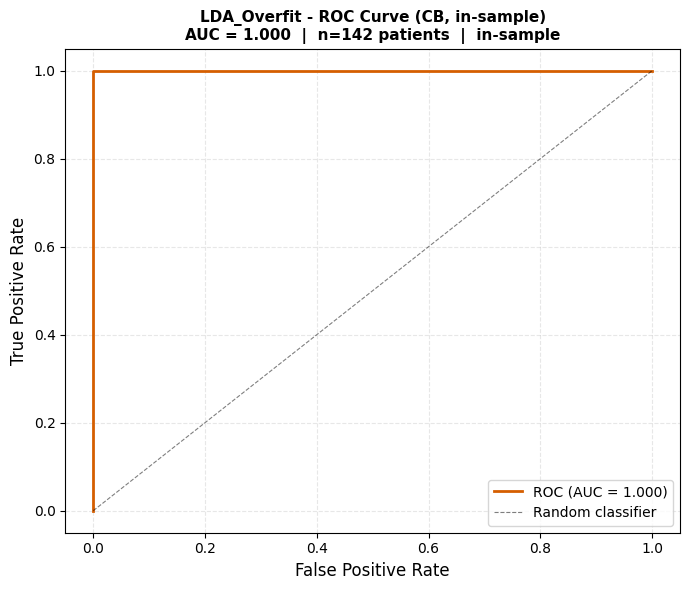

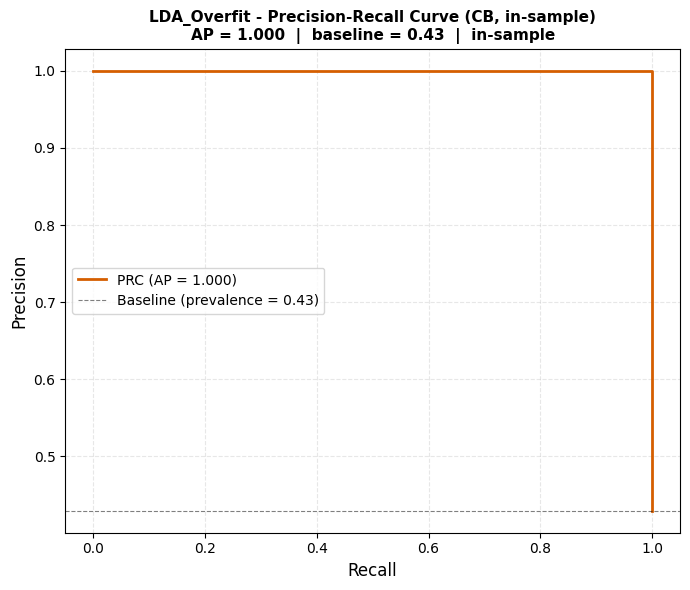

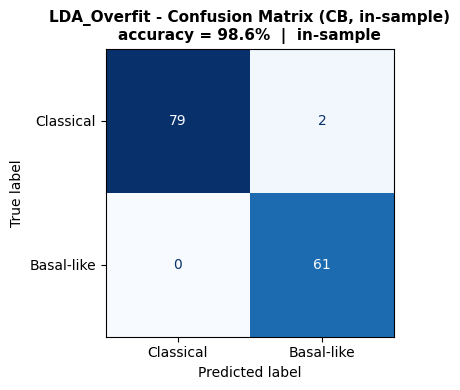

CB in-sample:  AUC=1.0000  AP=1.0000  acc=98.6%


In [7]:
# All metrics are in-sample (training set) since this is an overfit notebook.
scores_cb_insample = lda_cb.decision_function(X_cb_sc)
y_pred_cb_insample = (scores_cb_insample > 0).astype(int)
auc_cb_insample    = roc_auc_score(y_binary, scores_cb_insample)
ap_cb_insample     = average_precision_score(y_binary, scores_cb_insample)
acc_cb_insample    = float((y_pred_cb_insample == y_binary).mean())
baseline_cb        = float((y_binary == 1).mean())

# ROC
fpr_cb, tpr_cb, _ = roc_curve(y_binary, scores_cb_insample)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr_cb, tpr_cb, color=WONG['vermilion'], lw=2,
        label=f'ROC (AUC = {auc_cb_insample:.3f})')
ax.plot([0, 1], [0, 1], color='black', ls='--', lw=0.8, alpha=0.5,
        label='Random classifier')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title(
    f'LDA_Overfit - ROC Curve (CB, in-sample)\n'
    f'AUC = {auc_cb_insample:.3f}  |  n={len(y_binary)} patients  |  in-sample',
    fontsize=11, fontweight='bold',
)
ax.legend(fontsize=10)
ax.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'LDA_Overfit_cb_roc.png', dpi=150, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    plt.savefig(RESULTS_DIR / 'LDA_Overfit_cb_roc.svg', bbox_inches='tight')
plt.show()

# AUPRC
precision_cb, recall_cb, _ = precision_recall_curve(y_binary, scores_cb_insample)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(recall_cb, precision_cb, color=WONG['vermilion'], lw=2,
        label=f'PRC (AP = {ap_cb_insample:.3f})')
ax.axhline(baseline_cb, color='black', lw=0.8, ls='--', alpha=0.5,
           label=f'Baseline (prevalence = {baseline_cb:.2f})')
ax.set_xlabel('Recall', fontsize=12)
ax.set_ylabel('Precision', fontsize=12)
ax.set_title(
    f'LDA_Overfit - Precision-Recall Curve (CB, in-sample)\n'
    f'AP = {ap_cb_insample:.3f}  |  baseline = {baseline_cb:.2f}  |  in-sample',
    fontsize=11, fontweight='bold',
)
ax.legend(fontsize=10)
ax.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'LDA_Overfit_cb_prc.png', dpi=150, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    plt.savefig(RESULTS_DIR / 'LDA_Overfit_cb_prc.svg', bbox_inches='tight')
plt.show()

# Confusion matrix
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_binary, y_pred_cb_insample,
    display_labels=['Classical', 'Basal-like'],
    cmap='Blues', ax=ax, colorbar=False,
)
ax.set_title(
    f'LDA_Overfit - Confusion Matrix (CB, in-sample)\n'
    f'accuracy = {acc_cb_insample:.1%}  |  in-sample',
    fontsize=11, fontweight='bold',
)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'LDA_Overfit_cb_confusion.png', dpi=150, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    plt.savefig(RESULTS_DIR / 'LDA_Overfit_cb_confusion.svg', bbox_inches='tight')
plt.show()
print(f'CB in-sample:  AUC={auc_cb_insample:.4f}  AP={ap_cb_insample:.4f}  acc={acc_cb_insample:.1%}')

## 5c. Metrics - Healthy vs PDAC (In-Sample)

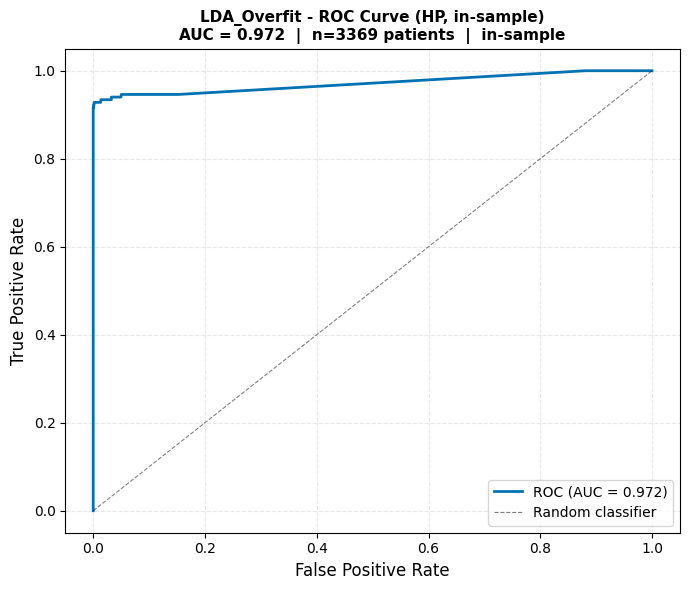

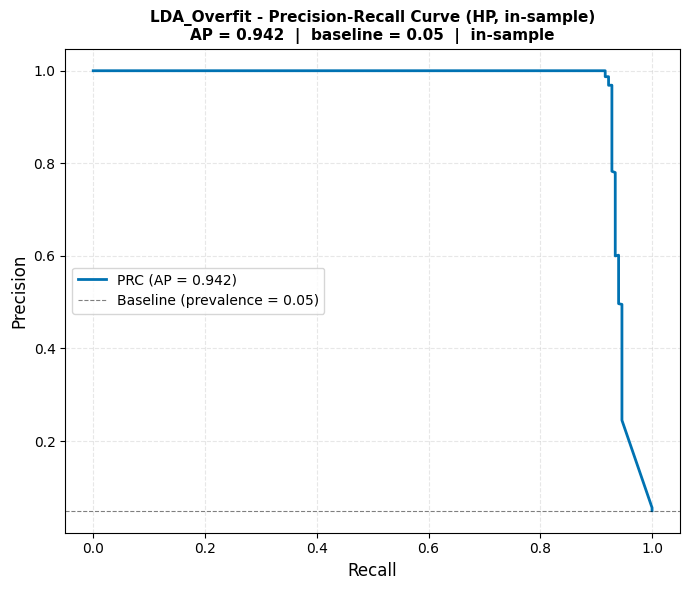

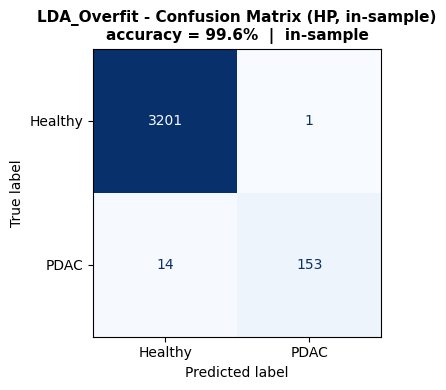

HP in-sample:  AUC=0.9716  AP=0.9421  acc=99.6%


In [8]:
scores_hp_insample = lda_hp.decision_function(X_hp_sc)
y_pred_hp_insample = (scores_hp_insample > 0).astype(int)
auc_hp_insample    = roc_auc_score(y_hp, scores_hp_insample)
ap_hp_insample     = average_precision_score(y_hp, scores_hp_insample)
acc_hp_insample    = float((y_pred_hp_insample == y_hp).mean())
baseline_hp        = float((y_hp == 1).mean())

# ROC
fpr_hp, tpr_hp, _ = roc_curve(y_hp, scores_hp_insample)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr_hp, tpr_hp, color=WONG['blue'], lw=2,
        label=f'ROC (AUC = {auc_hp_insample:.3f})')
ax.plot([0, 1], [0, 1], color='black', ls='--', lw=0.8, alpha=0.5,
        label='Random classifier')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title(
    f'LDA_Overfit - ROC Curve (HP, in-sample)\n'
    f'AUC = {auc_hp_insample:.3f}  |  n={len(y_hp)} patients  |  in-sample',
    fontsize=11, fontweight='bold',
)
ax.legend(fontsize=10)
ax.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'LDA_Overfit_hp_roc.png', dpi=150, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    plt.savefig(RESULTS_DIR / 'LDA_Overfit_hp_roc.svg', bbox_inches='tight')
plt.show()

# AUPRC
precision_hp, recall_hp, _ = precision_recall_curve(y_hp, scores_hp_insample)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(recall_hp, precision_hp, color=WONG['blue'], lw=2,
        label=f'PRC (AP = {ap_hp_insample:.3f})')
ax.axhline(baseline_hp, color='black', lw=0.8, ls='--', alpha=0.5,
           label=f'Baseline (prevalence = {baseline_hp:.2f})')
ax.set_xlabel('Recall', fontsize=12)
ax.set_ylabel('Precision', fontsize=12)
ax.set_title(
    f'LDA_Overfit - Precision-Recall Curve (HP, in-sample)\n'
    f'AP = {ap_hp_insample:.3f}  |  baseline = {baseline_hp:.2f}  |  in-sample',
    fontsize=11, fontweight='bold',
)
ax.legend(fontsize=10)
ax.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'LDA_Overfit_hp_prc.png', dpi=150, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    plt.savefig(RESULTS_DIR / 'LDA_Overfit_hp_prc.svg', bbox_inches='tight')
plt.show()

# Confusion matrix
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_hp, y_pred_hp_insample,
    display_labels=['Healthy', 'PDAC'],
    cmap='Blues', ax=ax, colorbar=False,
)
ax.set_title(
    f'LDA_Overfit - Confusion Matrix (HP, in-sample)\n'
    f'accuracy = {acc_hp_insample:.1%}  |  in-sample',
    fontsize=11, fontweight='bold',
)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'LDA_Overfit_hp_confusion.png', dpi=150, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    plt.savefig(RESULTS_DIR / 'LDA_Overfit_hp_confusion.svg', bbox_inches='tight')
plt.show()
print(f'HP in-sample:  AUC={auc_hp_insample:.4f}  AP={ap_hp_insample:.4f}  acc={acc_hp_insample:.1%}')

## 6b. Bootstrap Uncertainty

**HP (Healthy vs PDAC):** Re-runs per-individual healthy variant subsampling `N_BOOTSTRAP` times
with fresh seeds; TCGA patients are fixed. Bar heights = **mean coefficient** across iterations;
ranking = **mean |coef|**. Error bars = 95% CI (2.5th–97.5th percentile).

**CB (Classical vs Basal-like):** Draws `CB_SUBSAMPLE_FRAC × 142` patients without replacement
per iteration, refits LDA. Bar heights = **full-data coefficient** (all 142 patients);
ranking unchanged. Error bars = 95% CI from the subsampling distribution.

**Rank stability %** = fraction of iterations where the pathway appeared in the top 20
by |coefficient|. Set `BOOTSTRAP = False` in cell 0 to skip (fast).

In [9]:
# ── Bootstrap uncertainty quantification ──────────────────────────────────────
# HP: re-run healthy subsampling N times (TCGA patients fixed).
#     Bar heights = mean bootstrap coef; ranking = mean |coef|.
# CB: subsample 80% of 142 patients without replacement N times.
#     Bar heights = full-data coef (all 142); ranking unchanged.

if not BOOTSTRAP:
    mean_coef_hp = coefs_hp_boot = ci_hp_lo = ci_hp_hi = rank_stab_hp = top_hp_boot = None
    coefs_cb_boot = ci_cb_lo = ci_cb_hi = rank_stab_cb = None
    print('Bootstrap skipped (BOOTSTRAP=False)')
else:
    # ── Pre-slice TCGA rows — fixed across all HP iterations ─────────────────
    X_hp_tcga = X_hp[:len(pdac_ids), :]   # (167 × n_pathways)

    # ── HP bootstrap ─────────────────────────────────────────────────────────
    coefs_hp_boot = np.zeros((N_BOOTSTRAP, len(pw_names)))

    for i in tqdm(range(N_BOOTSTRAP), desc='Bootstrap HP'):
        rng_i = np.random.default_rng(RANDOM_SEED + i + 1)   # +1 avoids seed-42 collision

        healthy_gene_sets_boot: dict[str, set] = {}
        for sid in healthy_ids:
            variants = indiv_variants.get(sid, [])
            k = int(rng_i.choice(tcga_counts))
            k = min(k, len(variants))
            if k == 0:
                healthy_gene_sets_boot[sid] = set()
                continue
            indices  = rng_i.choice(len(variants), size=k, replace=False)
            genes_out = {variants[j][0] for j in indices if variants[j][1] >= AM_THRESHOLD}
            healthy_gene_sets_boot[sid] = genes_out

        X_hp_healthy_boot = build_binary_matrix(
            healthy_ids, healthy_gene_sets_boot, pw_names, pw_sets
        )
        X_hp_boot_i = np.vstack([X_hp_tcga, X_hp_healthy_boot])

        sc_i = StandardScaler()
        X_sc = sc_i.fit_transform(X_hp_boot_i)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            lda_i = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
            lda_i.fit(X_sc, y_hp)
        coefs_hp_boot[i] = lda_i.coef_[0]

    mean_coef_hp = coefs_hp_boot.mean(axis=0)
    ci_hp_lo     = np.percentile(coefs_hp_boot,  2.5, axis=0)
    ci_hp_hi     = np.percentile(coefs_hp_boot, 97.5, axis=0)
    top_hp_boot  = np.argsort(np.abs(mean_coef_hp))[::-1][:TOP_N]

    rank_stab_hp = np.zeros(len(pw_names))
    for i in range(N_BOOTSTRAP):
        for idx in np.argsort(np.abs(coefs_hp_boot[i]))[::-1][:TOP_N]:
            rank_stab_hp[idx] += 1
    rank_stab_hp /= N_BOOTSTRAP

    print('HP bootstrap top-5 (ranked by mean |coef|):')
    for j in top_hp_boot[:5]:
        tag = pw_level_tag(pw_names[j])
        print(f'  {pw_names[j]} {tag}  '
              f'mean={mean_coef_hp[j]:+.4f}  '
              f'95%CI=[{ci_hp_lo[j]:+.4f}, {ci_hp_hi[j]:+.4f}]  '
              f'stability={rank_stab_hp[j]*100:.0f}%')
    print()

    # ── CB bootstrap: 80% subsample without replacement ──────────────────────
    n_cb_sub      = round(len(clvbl_ids) * CB_SUBSAMPLE_FRAC)
    coefs_cb_boot = np.zeros((N_BOOTSTRAP, len(pw_names)))

    for i in tqdm(range(N_BOOTSTRAP), desc='Bootstrap CB'):
        rng_i    = np.random.default_rng(RANDOM_SEED + i + 1)
        boot_idx = rng_i.choice(len(clvbl_ids), size=n_cb_sub, replace=False)
        X_cb_b   = X_cb[boot_idx, :]
        y_cb_b   = y_binary[boot_idx]

        sc_i = StandardScaler()
        X_sc = sc_i.fit_transform(X_cb_b)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            lda_i = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
            lda_i.fit(X_sc, y_cb_b)
        coefs_cb_boot[i] = lda_i.coef_[0]

    ci_cb_lo = np.percentile(coefs_cb_boot,  2.5, axis=0)
    ci_cb_hi = np.percentile(coefs_cb_boot, 97.5, axis=0)

    rank_stab_cb = np.zeros(len(pw_names))
    for i in range(N_BOOTSTRAP):
        for idx in np.argsort(np.abs(coefs_cb_boot[i]))[::-1][:TOP_N]:
            rank_stab_cb[idx] += 1
    rank_stab_cb /= N_BOOTSTRAP

    print(f'CB bootstrap: {n_cb_sub}/{len(clvbl_ids)} patients per iteration '
          f'({CB_SUBSAMPLE_FRAC*100:.0f}% without replacement)')
    print('CB bootstrap top-5 (ranked by full-data |coef|):')
    for j in top_cb[:5]:
        tag = pw_level_tag(pw_names[j])
        print(f'  {pw_names[j]} {tag}  '
              f'coef={coef_cb[j]:+.4f}  '
              f'95%CI=[{ci_cb_lo[j]:+.4f}, {ci_cb_hi[j]:+.4f}]  '
              f'stability={rank_stab_cb[j]*100:.0f}%')

Bootstrap HP:   0%|          | 0/100 [00:00<?, ?it/s]

HP bootstrap top-5 (ranked by mean |coef|):
  REACTOME_Diseases of signal transduction by growth factor receptors and second messengers (Reactome-L2)  mean=+8.7495  95%CI=[+6.8060, +10.7769]  stability=100%
  REACTOME_Transcriptional regulation by RUNX3 (Reactome-L4)  mean=+4.4411  95%CI=[+1.4180, +6.8843]  stability=100%
  REACTOME_Cytokine Signaling in Immune system (Reactome-L2)  mean=+2.7484  95%CI=[+2.1409, +3.3733]  stability=100%
  REACTOME_Transmission across Chemical Synapses (Reactome-L2)  mean=+2.5143  95%CI=[+1.9241, +3.1779]  stability=100%
  REACTOME_Neurotransmitter receptors and postsynaptic signal transmission (Reactome-L3)  mean=+2.0481  95%CI=[+1.5236, +2.5353]  stability=100%



Bootstrap CB:   0%|          | 0/100 [00:00<?, ?it/s]

CB bootstrap: 114/142 patients per iteration (80% without replacement)
CB bootstrap top-5 (ranked by full-data |coef|):
  HALLMARK_KRAS Signaling Up   coef=+0.9224  95%CI=[+0.5865, +1.2380]  stability=96%
  REACTOME_Formation of the cornified envelope (Reactome-L3)  coef=+0.8083  95%CI=[+0.5440, +1.1921]  stability=92%
  HALLMARK_Fatty Acid Metabolism   coef=+0.7397  95%CI=[+0.2910, +1.0578]  stability=71%
  REACTOME_Generic Transcription Pathway (Reactome-L3)  coef=-0.6821  95%CI=[-1.2357, -0.2944]  stability=66%
  REACTOME_RNA Polymerase II Transcription (Reactome-L2)  coef=-0.6821  95%CI=[-1.2357, -0.2944]  stability=66%


## 6. Diverging Bar Chart

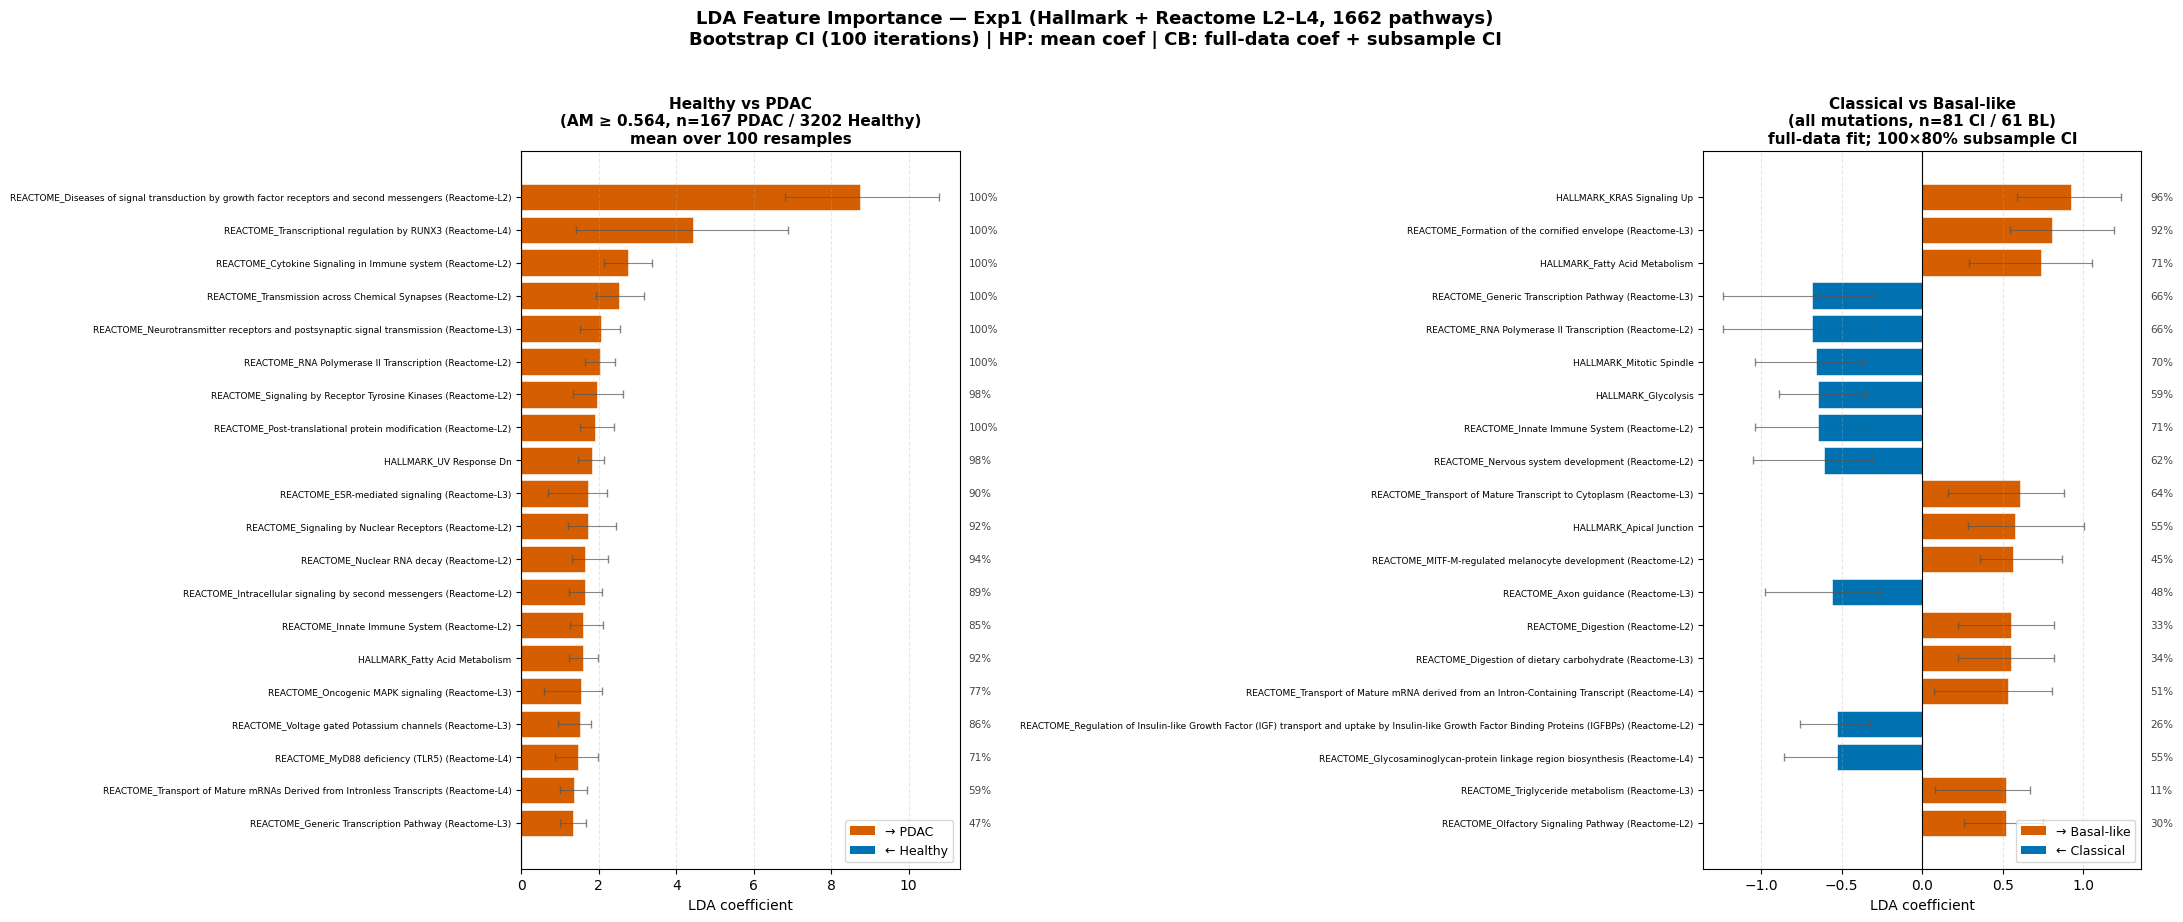

Figure saved → C:\Users\daane\Desktop\DATA\results\LDA_Overfit_feature_importance.png


In [10]:
from matplotlib.patches import Patch
from matplotlib.transforms import blended_transform_factory

# ── Prepare data for each panel ────────────────────────────────────────────────
if BOOTSTRAP:
    hp_top_ordered = top_hp_boot[::-1]   # bottom-to-top so rank 1 is at top
    hp_vals        = [mean_coef_hp[i] for i in hp_top_ordered]
    hp_ci_lo       = [mean_coef_hp[i] - ci_hp_lo[i] for i in hp_top_ordered]
    hp_ci_hi       = [ci_hp_hi[i] - mean_coef_hp[i] for i in hp_top_ordered]
    hp_stab        = [rank_stab_hp[i]               for i in hp_top_ordered]
    hp_coef_label  = f'mean over {N_BOOTSTRAP} resamples'
else:
    hp_top_ordered = top_hp[::-1]
    hp_vals        = [coef_hp[i] for i in hp_top_ordered]
    hp_ci_lo = hp_ci_hi = hp_stab = None
    hp_coef_label  = 'full-data fit'

cb_top_ordered = top_cb[::-1]   # always full-data ranked
cb_vals        = [coef_cb[i] for i in cb_top_ordered]
if BOOTSTRAP:
    cb_ci_lo  = [coef_cb[i] - ci_cb_lo[i] for i in cb_top_ordered]
    cb_ci_hi  = [ci_cb_hi[i] - coef_cb[i] for i in cb_top_ordered]
    cb_stab   = [rank_stab_cb[i]           for i in cb_top_ordered]
else:
    cb_ci_lo = cb_ci_hi = cb_stab = None

fig, axes = plt.subplots(1, 2, figsize=(22, 9))

panels = [
    (axes[0], hp_top_ordered, hp_vals, hp_ci_lo, hp_ci_hi, hp_stab,
     f'Healthy vs PDAC\n'
     f'(AM ≥ {AM_THRESHOLD}, n={(y_hp==1).sum()} PDAC / {(y_hp==0).sum()} Healthy)\n'
     f'{hp_coef_label}',
     '→ PDAC', '← Healthy'),
    (axes[1], cb_top_ordered, cb_vals, cb_ci_lo, cb_ci_hi, cb_stab,
     'Classical vs Basal-like\n'
     f'(all mutations, n={len(classical_ids)} Cl / {len(basal_ids)} BL)\nfull-data fit'
     + (f'; {N_BOOTSTRAP}×{round(CB_SUBSAMPLE_FRAC*100):.0f}% subsample CI'
        if BOOTSTRAP else ''),
     '→ Basal-like', '← Classical'),
]

for ax, top_ordered, vals, ci_lo, ci_hi, stab, task_label, pos_label, neg_label in panels:
    labels = []
    for i in top_ordered:
        name = pw_names[i]
        tag  = pw_level_tag(name)
        labels.append(f'{name} {tag}'.strip())

    colors = [WONG['vermilion'] if v > 0 else WONG['blue'] for v in vals]
    y_pos  = range(len(vals))

    xerr = [ci_lo, ci_hi] if (BOOTSTRAP and ci_lo is not None) else None
    ax.barh(
        y_pos, vals,
        xerr=xerr,
        error_kw={'ecolor': '#555555', 'capsize': 3, 'linewidth': 0.8, 'alpha': 0.7},
        color=colors, edgecolor='white', linewidth=0.4,
    )
    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels, fontsize=6.5)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel('LDA coefficient', fontsize=10)
    ax.set_title(task_label, fontsize=11, fontweight='bold')
    ax.grid(axis='x', alpha=0.3, linestyle='--')
    ax.legend(
        handles=[
            Patch(facecolor=WONG['vermilion'], label=pos_label),
            Patch(facecolor=WONG['blue'],      label=neg_label),
        ],
        loc='lower right', fontsize=9,
    )

    # Rank stability % at fixed right-margin column (axes-fraction x, data y)
    if BOOTSTRAP and stab is not None:
        trans = blended_transform_factory(ax.transAxes, ax.transData)
        for y, s in zip(y_pos, stab):
            ax.text(
                1.02, y, f'{s * 100:.0f}%',
                transform=trans, va='center', ha='left',
                fontsize=7.5, color='#444444',
            )

_reactome_label = f'Reactome L{MIN_REACTOME_LEVEL+1}–L{MAX_REACTOME_LEVEL+1}'
plt.suptitle(
    f'LDA Feature Importance — Exp1 (Hallmark + {_reactome_label}, {len(pw_sets)} pathways)\n'
    + ('Full-data fit (visualization only, not cross-validated)'
       if not BOOTSTRAP else
       f'Bootstrap CI ({N_BOOTSTRAP} iterations) | HP: mean coef | CB: full-data coef + subsample CI'),
    fontsize=13, fontweight='bold', y=1.02,
)
plt.tight_layout()

out_fig = RESULTS_DIR / 'LDA_Overfit_feature_importance.png'
plt.savefig(out_fig, dpi=150, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    plt.savefig(out_fig.with_suffix('.svg'), bbox_inches='tight')
plt.show()
print(f'Figure saved → {out_fig}')

## 7. Hierarchical Scatter Plot

Each point is one patient. **X-axis** = HP LDA raw score (AM-filtered features, all 3369 patients).
**Y-axis** = CB LDA raw score (all-mutation features, fitted on 142 labeled TCGA; extrapolated to
uncertain and healthy via `scaler_cb.transform` + `lda_cb.transform`).

Healthy patients are subsampled to 300 for display clarity.  
Both LDAs are full-data fits (overfit) — no cross-validation.

X_unc_cb  : (25, 1662)   density=9.2%
X_hlt_cb  : (3202, 1662)  density=86.3%


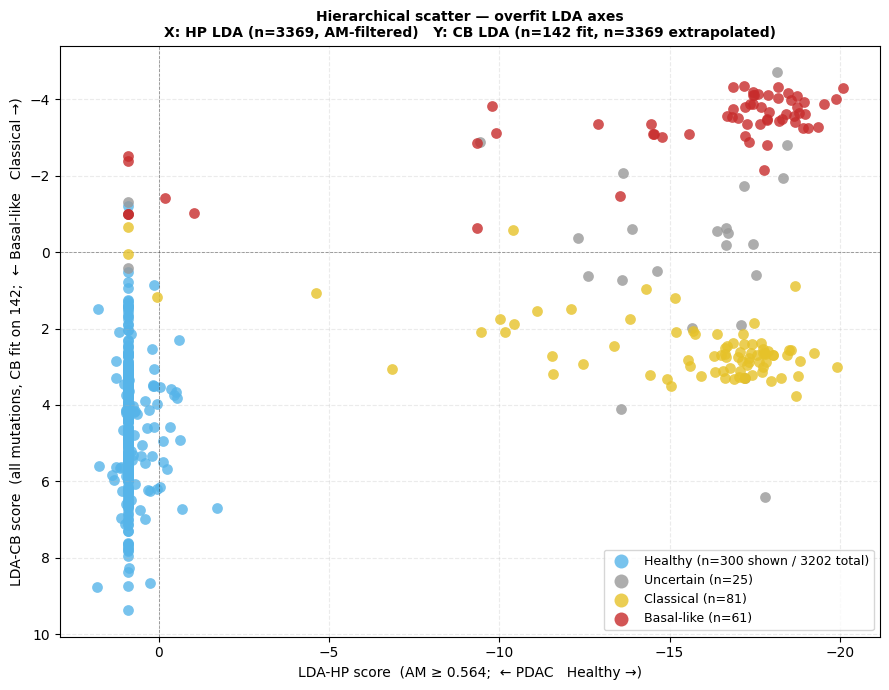

Scatter saved → C:\Users\daane\Desktop\DATA\results\LDA_Overfit_scatter.png


In [11]:
# ── CB feature matrices for extrapolation to uncertain + healthy ───────────────
# Uncertain TCGA (25): all mutations, no AM filter
df_tcga_unc = (
    pl.read_parquet(
        PARQUET,
        columns=['source', 'sample_id', 'gene_symbol', 'gene_name'],
    )
    .filter(
        (pl.col('source') == 'TCGA') &
        pl.col('sample_id').is_in(uncertain_ids)
    )
    .with_columns(pl.coalesce(['gene_symbol', 'gene_name']).alias('gene'))
    .drop_nulls('gene')
    .select(['sample_id', 'gene'])
    .unique()
)
tcga_unc_gene_sets: dict[str, set] = {}
for row in (
    df_tcga_unc.group_by('sample_id').agg(pl.col('gene')).iter_rows(named=True)
):
    tcga_unc_gene_sets[row['sample_id']] = set(row['gene'])

# Healthy (3202): all 1000G mutations, no filter, no subsampling
# Reuse df_1kg_all loaded in Cell 4; take all genes per individual
healthy_all_gene_sets: dict[str, set] = {}
for row in (
    df_1kg_all.group_by('sample_id').agg(pl.col('gene')).iter_rows(named=True)
):
    healthy_all_gene_sets[row['sample_id']] = set(row['gene'])

X_unc_cb = build_binary_matrix(uncertain_ids, tcga_unc_gene_sets,    pw_names, pw_sets)
X_hlt_cb = build_binary_matrix(healthy_ids,   healthy_all_gene_sets, pw_names, pw_sets)

# Apply CB scaler (mean/std from 142 PDAC patients) then CB LDA
X_unc_cb_sc = scaler_cb.transform(X_unc_cb)
X_hlt_cb_sc = scaler_cb.transform(X_hlt_cb)

print(f'X_unc_cb  : {X_unc_cb.shape}   density={100*(X_unc_cb>0).mean():.1f}%')
print(f'X_hlt_cb  : {X_hlt_cb.shape}  density={100*(X_hlt_cb>0).mean():.1f}%')

# ── LDA scores ─────────────────────────────────────────────────────────────────
# HP: all 3369 patients (pdac_ids first, then healthy_ids)
scores_hp_all = lda_hp.transform(X_hp_sc).ravel()
n_pdac        = len(pdac_ids)
scores_hp_clvbl = scores_hp_all[:len(clvbl_ids)]
scores_hp_unc   = scores_hp_all[len(clvbl_ids):n_pdac]
scores_hp_hlt   = scores_hp_all[n_pdac:]

# CB: per group
scores_cb_clvbl = lda_cb.transform(X_cb_sc).ravel()
scores_cb_unc   = lda_cb.transform(X_unc_cb_sc).ravel()
scores_cb_hlt   = lda_cb.transform(X_hlt_cb_sc).ravel()

# ── Scatter plot ───────────────────────────────────────────────────────────────
DOT_SIZE = 60
ALPHA    = 0.80

rng_scatter = np.random.default_rng(RANDOM_SEED)
hlt_sub = rng_scatter.choice(len(scores_hp_hlt), size=min(300, len(scores_hp_hlt)), replace=False)

cl_mask = y_binary == 0
bl_mask = y_binary == 1

fig, ax = plt.subplots(figsize=(9, 7))

ax.scatter(
    scores_hp_hlt[hlt_sub], scores_cb_hlt[hlt_sub],
    c=WONG['sky_blue'], s=DOT_SIZE, alpha=ALPHA, linewidths=0, zorder=1,
    label=f'Healthy (n=300 shown / {len(healthy_ids)} total)',
)
ax.scatter(
    scores_hp_unc, scores_cb_unc,
    c=GRAY, s=DOT_SIZE, alpha=ALPHA, linewidths=0, zorder=3,
    label=f'Uncertain (n={len(uncertain_ids)})',
)
ax.scatter(
    scores_hp_clvbl[cl_mask], scores_cb_clvbl[cl_mask],
    c=YELLOW_WARM, s=DOT_SIZE, alpha=ALPHA, linewidths=0, zorder=4,
    label=f'Classical (n={cl_mask.sum()})',
)
ax.scatter(
    scores_hp_clvbl[bl_mask], scores_cb_clvbl[bl_mask],
    c=RED_DEEP, s=DOT_SIZE, alpha=ALPHA, linewidths=0, zorder=4,
    label=f'Basal-like (n={bl_mask.sum()})',
)

ax.invert_xaxis()
ax.invert_yaxis()

ax.axvline(0, color='black', lw=0.6, ls='--', alpha=0.4)
ax.axhline(0, color='black', lw=0.6, ls='--', alpha=0.4)
ax.set_xlabel(
    f'LDA-HP score  (AM ≥ {AM_THRESHOLD};  ← PDAC   Healthy →)',
    fontsize=10,
)
ax.set_ylabel(
    'LDA-CB score  (all mutations, CB fit on 142;  ← Basal-like   Classical →)',
    fontsize=10,
)
ax.set_title(
    'Hierarchical scatter — overfit LDA axes\n'
    f'X: HP LDA (n={len(y_hp)}, AM-filtered)   '
    f'Y: CB LDA (n={len(y_binary)} fit, n={len(y_hp)} extrapolated)',
    fontsize=10, fontweight='bold',
)
ax.legend(fontsize=9, markerscale=1.3)
ax.grid(alpha=0.25, linestyle='--')
plt.tight_layout()

out_scatter = RESULTS_DIR / 'LDA_Overfit_scatter.png'
plt.savefig(out_scatter, dpi=150, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    plt.savefig(out_scatter.with_suffix('.svg'), bbox_inches='tight')
plt.show()
print(f'Scatter saved → {out_scatter}')

## 8. Per-Gene Mutation Counts

Counts are derived from the **same filtered/subsampled gene sets** used to build the feature
matrices — ensuring consistency between the LDA features and the gene breakdown display.

In [12]:
# HP: AM-filtered TCGA gene counts
gene_pdac_count: dict[str, int] = defaultdict(int)
for sid in pdac_ids:
    for g in tcga_hp_gene_sets.get(sid, set()):
        gene_pdac_count[g] += 1

# HP: subsampled + AM-filtered healthy gene counts
gene_healthy_count: dict[str, int] = defaultdict(int)
for sid in healthy_ids:
    for g in healthy_hp_gene_sets.get(sid, set()):
        gene_healthy_count[g] += 1

# CB: all TCGA mutations for classical patients
gene_classical_count: dict[str, int] = defaultdict(int)
for sid in classical_ids:
    for g in tcga_cb_gene_sets.get(sid, set()):
        gene_classical_count[g] += 1

# CB: all TCGA mutations for basal-like patients
gene_basal_count: dict[str, int] = defaultdict(int)
for sid in basal_ids:
    for g in tcga_cb_gene_sets.get(sid, set()):
        gene_basal_count[g] += 1

n_pdac_total      = len(pdac_ids)
n_healthy_total   = len(healthy_ids)
n_classical_total = len(classical_ids)
n_basal_total     = len(basal_ids)

# Spot-check canonical drivers
print('Spot-check: KRAS in HP task (AM-filtered gene sets)')
print(f'  PDAC   : {gene_pdac_count["KRAS"]} / {n_pdac_total} '
      f'({100*gene_pdac_count["KRAS"]/n_pdac_total:.1f}%)')
print(f'  Healthy: {gene_healthy_count["KRAS"]} / {n_healthy_total} '
      f'({100*gene_healthy_count["KRAS"]/n_healthy_total:.2f}%)')
print()
print('Spot-check: KRAS in CB task (all mutations)')
print(f'  Classical : {gene_classical_count["KRAS"]} / {n_classical_total} '
      f'({100*gene_classical_count["KRAS"]/n_classical_total:.1f}%)')
print(f'  Basal-like: {gene_basal_count["KRAS"]} / {n_basal_total} '
      f'({100*gene_basal_count["KRAS"]/n_basal_total:.1f}%)')

Spot-check: KRAS in HP task (AM-filtered gene sets)
  PDAC   : 106 / 167 (63.5%)
  Healthy: 0 / 3202 (0.00%)

Spot-check: KRAS in CB task (all mutations)
  Classical : 51 / 81 (63.0%)
  Basal-like: 44 / 61 (72.1%)


## 9. Generate Text File

In [13]:
def gene_breakdown_lines(
    pathway_name: str,
    count_a: dict, n_a: int, label_a: str,
    count_b: dict | None = None, n_b: int = 0, label_b: str = '',
) -> list[str]:
    """
    Returns three formatted lines showing gene mutation fractions for one pathway.
    count_a / n_a / label_a = primary group (PDAC or Classical).
    count_b / n_b / label_b = secondary group (Healthy or Basal-like).
    """
    if pathway_name not in pw_sets:
        return ['         [pathway not found in pw_sets]']

    pathway_genes = pw_sets[pathway_name]

    def pct(count, total):
        return f'{100 * count / total:.1f}%' if total > 0 else '0.0%'

    def fmt(gene):
        ca = count_a.get(gene, 0)
        if count_b is not None:
            cb = count_b.get(gene, 0)
            return f'{gene} ({pct(ca, n_a)} {label_a} / {pct(cb, n_b)} {label_b})'
        return f'{gene} ({pct(ca, n_a)} {label_a})'

    def sort_key(gene):
        ca = count_a.get(gene, 0)
        cb = count_b.get(gene, 0) if count_b is not None else 0
        return ca + cb

    def has_count(gene):
        return sort_key(gene) > 0

    canonical = [fmt(g) for g in sorted(CANONICAL_DRIVERS)
                 if g in pathway_genes and has_count(g)]
    custom    = [fmt(g) for g in sorted(CUSTOM_DRIVERS)
                 if g in pathway_genes and has_count(g)]

    driver_all  = CANONICAL_DRIVERS | CUSTOM_DRIVERS
    other_genes = pathway_genes - driver_all
    other_ranked = sorted(
        [g for g in other_genes if has_count(g)],
        key=sort_key, reverse=True,
    )[:TOP_OTHER]
    other = [fmt(g) for g in other_ranked]

    prefix = '         '
    return [
        f'{prefix}Canonical drivers:     ' + (', '.join(canonical) if canonical else '[none]'),
        f'{prefix}Custom drivers (73):   ' + (', '.join(custom) if custom else '[none]'),
        f'{prefix}Other genes (top {TOP_OTHER}): ' + (', '.join(other) if other else '[none]'),
    ]


# ── Select HP display ranking (bootstrap-mean or full-data) ───────────────────
hp_display      = top_hp_boot if BOOTSTRAP else top_hp
coef_hp_display = mean_coef_hp if BOOTSTRAP else coef_hp

hp_ranking_note = (
    f'Ranked by mean |coef| over {N_BOOTSTRAP} bootstrap resamples'
    if BOOTSTRAP else 'Ranked by full-data |coef|'
)

# ── Build output lines ─────────────────────────────────────────────────────────
lines = []

_reactome_label = f'Reactome L{MIN_REACTOME_LEVEL+1}–L{MAX_REACTOME_LEVEL+1}'

lines.append('=' * 80)
lines.append(f'LDA Feature Importance — LDA_Overfit (Hallmark + {_reactome_label}, {len(pw_sets)} pathways)')
lines.append('Fitted on full dataset (interpretation only; not cross-validated)')
lines.append('Top 20 pathways ranked by |LDA coefficient|')
lines.append(f'HP task: AM-filtered mutations only (am_pathogenicity >= {AM_THRESHOLD})')
lines.append('CB task: all TCGA mutations, no AM filter')
if BOOTSTRAP:
    lines.append(f'Bootstrap: {N_BOOTSTRAP} iterations | '
                 f'HP: mean coef, ranked by mean |coef| | '
                 f'CB: full-data coef, {round(CB_SUBSAMPLE_FRAC*100):.0f}% subsample CI')
lines.append('=' * 80)
lines.append('')

# ── TASK 1: Healthy vs PDAC ───────────────────────────────────────────────────
lines.append('-' * 80)
lines.append(f'TASK 1: Healthy vs PDAC  (AM-filtered: am_pathogenicity >= {AM_THRESHOLD})')
lines.append(f'  n = {len(y_hp)} patients  '
             f'(Healthy: {(y_hp==0).sum()}, PDAC: {(y_hp==1).sum()})')
lines.append('  Positive coefficient -> PDAC  |  Negative coefficient -> Healthy')
lines.append('  Healthy: subsample to TCGA count distribution, then apply AM filter')
lines.append(f'  Gene counts: PDAC n={n_pdac_total} (AM-filtered); '
             f'Healthy n={n_healthy_total} (subsampled+AM-filtered)')
lines.append(f'  {hp_ranking_note}')
lines.append('-' * 80)
lines.append(f'  {"Rank":<5}  {"Pathway":<67}  {"Coef":>9}  '
             + (f'{"Stability":>9}  ' if BOOTSTRAP else '')
             + f'{"Direction":<15}')
lines.append('  ' + '-' * (102 + (12 if BOOTSTRAP else 0)))

for rank, idx in enumerate(hp_display, 1):
    name  = pw_names[idx]
    tag   = pw_level_tag(name)
    label = f'{name} {tag}'.strip()
    coef  = coef_hp_display[idx]
    direc = '-> PDAC' if coef > 0 else '<- Healthy'
    stab_str = f'{rank_stab_hp[idx]*100:.0f}%' if BOOTSTRAP else ''
    lines.append(
        f'  {rank:<5}  {label:<67}  {coef:>+9.4f}  '
        + (f'{stab_str:>9}  ' if BOOTSTRAP else '')
        + f'{direc:<15}'
    )
    lines.extend(gene_breakdown_lines(
        name,
        gene_pdac_count,    n_pdac_total,    'PDAC',
        gene_healthy_count, n_healthy_total, 'Healthy',
    ))
    lines.append('')

# ── TASK 2: Classical vs Basal-like ───────────────────────────────────────────
lines.append('-' * 80)
lines.append('TASK 2: Classical vs Basal-like  (all TCGA mutations, no AM filter)')
lines.append(f'  n = {len(y_binary)} PDAC patients  '
             f'(Classical: {n_classical_total}, Basal-like: {n_basal_total})')
lines.append('  Positive coefficient -> Basal-like  |  Negative coefficient -> Classical')
lines.append(f'  Gene counts: Classical n={n_classical_total}, Basal-like n={n_basal_total}')
lines.append('  Ranked by full-data |coef| (all 142 patients)')
lines.append('-' * 80)
lines.append(f'  {"Rank":<5}  {"Pathway":<67}  {"Coef":>9}  '
             + (f'{"Stability":>9}  ' if BOOTSTRAP else '')
             + f'{"Direction":<20}')
lines.append('  ' + '-' * (107 + (12 if BOOTSTRAP else 0)))

for rank, idx in enumerate(top_cb, 1):
    name  = pw_names[idx]
    tag   = pw_level_tag(name)
    label = f'{name} {tag}'.strip()
    coef  = coef_cb[idx]
    direc = '-> Basal-like' if coef > 0 else '<- Classical'
    stab_str = f'{rank_stab_cb[idx]*100:.0f}%' if BOOTSTRAP else ''
    lines.append(
        f'  {rank:<5}  {label:<67}  {coef:>+9.4f}  '
        + (f'{stab_str:>9}  ' if BOOTSTRAP else '')
        + f'{direc:<20}'
    )
    lines.extend(gene_breakdown_lines(
        name,
        gene_classical_count, n_classical_total, 'Cl',
        gene_basal_count,     n_basal_total,     'BL',
    ))
    lines.append('')

lines.append('-' * 80)
lines.append('Notes:')
lines.append('  - LDA solver: eigen, shrinkage: auto (Ledoit-Wolf)')
lines.append('  - Features standardized (zero mean, unit variance) before fitting')
lines.append('  - Full-data fit for visualization/interpretation only (not cross-validated)')
lines.append(f'  - Data source: merged_tcga_1000G.parquet')
lines.append(f'  - AM threshold: {AM_THRESHOLD}')
lines.append(f'  - Healthy subsampling: k drawn from TCGA count distribution '
             f'(seed {RANDOM_SEED}), then AM filter applied to subsample')
lines.append(f'  - No AF frequency filter applied to 1000G variants')
lines.append(f'  - Exp1 feature set: Hallmark ({len(hallmark_sets)}) + {_reactome_label} ({len(reactome_selected)}) = {len(pw_sets)} pathways')
lines.append('  - Canonical drivers: KRAS, TP53, SMAD4, CDKN2A')
lines.append('  - Custom drivers: 73 genes from driver_like_genes.txt (excl. canonical 4)')
lines.append(f'  - Other genes: top {TOP_OTHER} non-driver mutated genes per pathway by total count')
if BOOTSTRAP:
    lines.append(f'  - HP bootstrap: {N_BOOTSTRAP} iterations, re-run healthy subsampling per iteration')
    lines.append(f'  - CB bootstrap: {N_BOOTSTRAP} iterations, '
                 f'{round(CB_SUBSAMPLE_FRAC*100):.0f}% subsample without replacement')
    lines.append('  - Stability %: fraction of bootstrap iterations where pathway was in top-20 by |coef|')
    lines.append('  - 95% CI: 2.5th–97.5th percentile of bootstrap coefficient distribution')
lines.append('-' * 80)

out_txt = RESULTS_DIR / 'LDA_Overfit_feature_importance.txt'
out_txt.write_text('\n'.join(lines), encoding='utf-8')
print(f'Written → {out_txt}')

Written → C:\Users\daane\Desktop\DATA\results\LDA_Overfit_feature_importance.txt
